
Step 0
Current state: (3, 1, 2, 0)
Current cost: 2


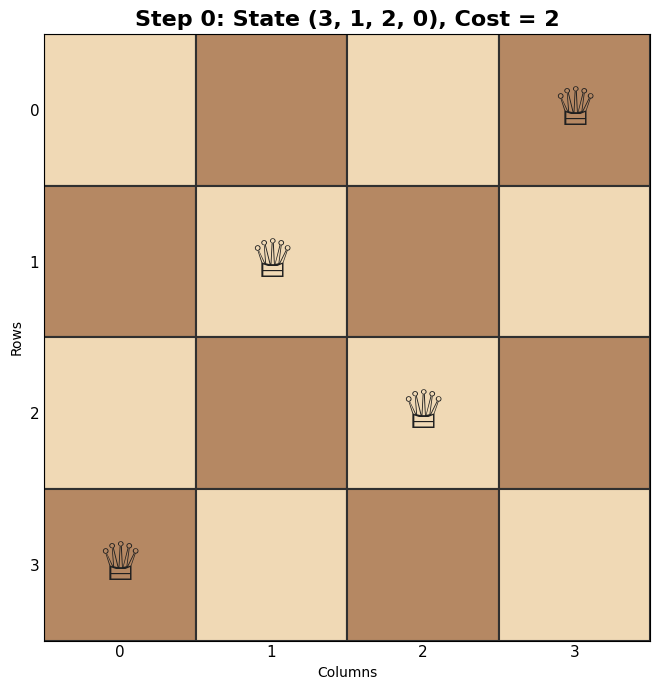


Neighbour costs:
Swap (0, 1): (1, 3, 2, 0), Cost = 1
Swap (0, 2): (2, 1, 3, 0), Cost = 1
Swap (0, 3): (0, 1, 2, 3), Cost = 6
Swap (1, 2): (3, 2, 1, 0), Cost = 6
Swap (1, 3): (3, 0, 2, 1), Cost = 1
Swap (2, 3): (3, 1, 0, 2), Cost = 1
Selected swap: (0, 1)
Next state: (1, 3, 2, 0)

Step 1
Current state: (1, 3, 2, 0)
Current cost: 1


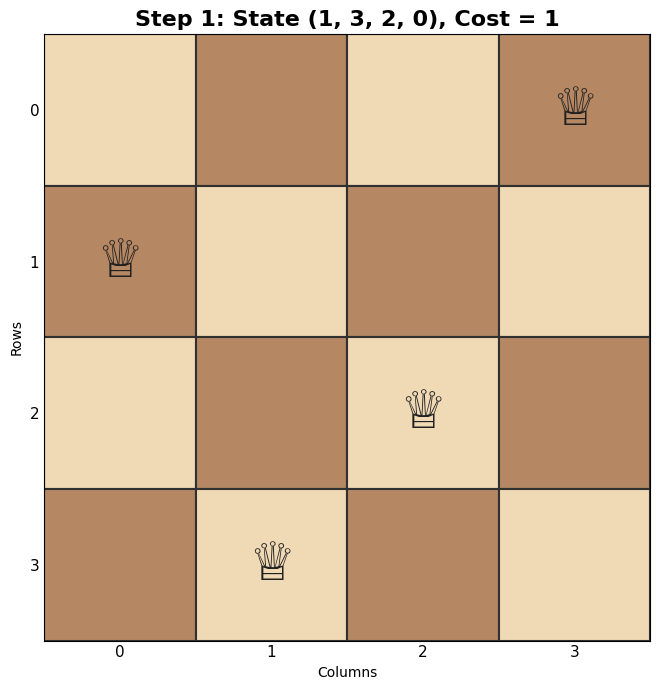


Neighbour costs:
Swap (0, 1): (3, 1, 2, 0), Cost = 2
Swap (0, 2): (2, 3, 1, 0), Cost = 2
Swap (0, 3): (0, 3, 2, 1), Cost = 4
Swap (1, 2): (1, 2, 3, 0), Cost = 4
Swap (1, 3): (1, 0, 2, 3), Cost = 2
Swap (2, 3): (1, 3, 0, 2), Cost = 0
Selected swap: (2, 3)
Next state: (1, 3, 0, 2)

Step 2
Current state: (1, 3, 0, 2)
Current cost: 0


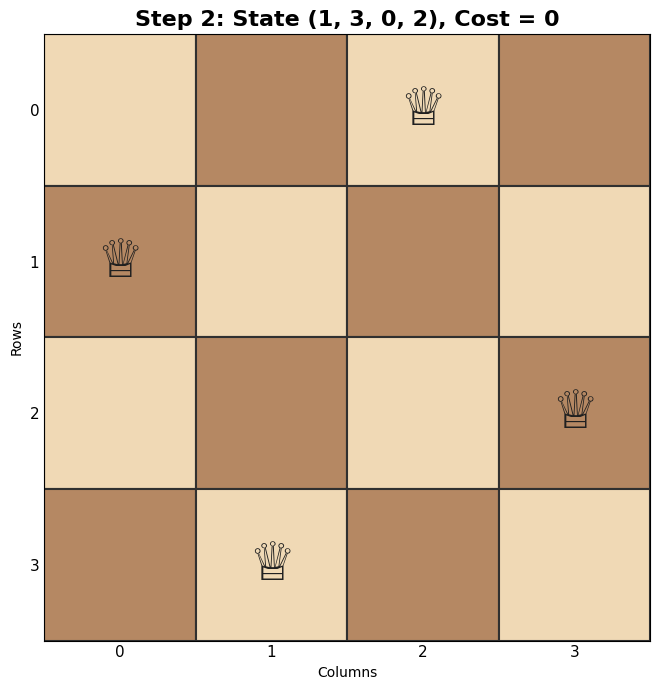

Goal state reached!

Final solution: (1, 3, 0, 2)
Final cost: 0


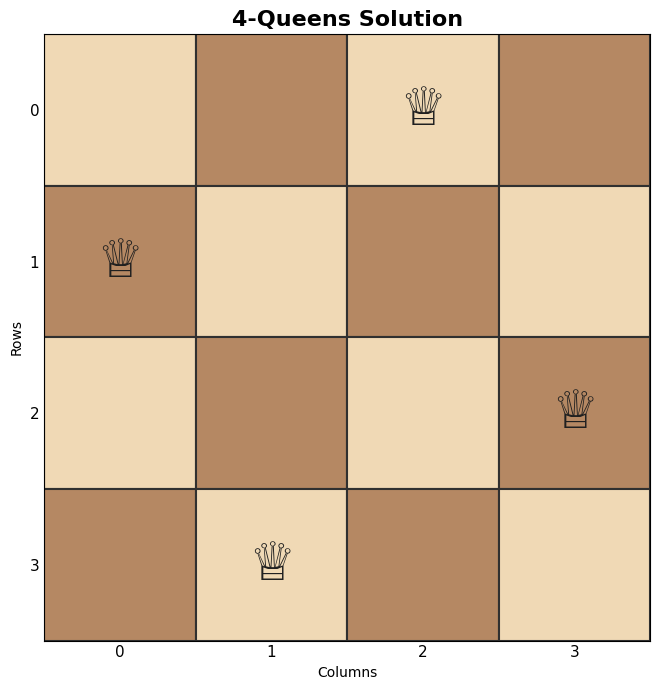

In [2]:

from itertools import combinations
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

N = 4

def calculate_cost(state):
    conflicts = 0
    for i in range(N):
        for j in range(i + 1, N):
            if (state[i] == state[j] or
                abs(state[i] - state[j]) == abs(i - j)):
                conflicts += 1
    return conflicts


def generate_neighbours(state):
    neighbours = []

    for i, j in combinations(range(N), 2):
        new_state = list(state)
        new_state[i], new_state[j] = new_state[j], new_state[i]
        new_state = tuple(new_state)

        neighbours.append(
            ((i, j), new_state, calculate_cost(new_state))
        )

    return neighbours


def display_board(state, title):
    fig, ax = plt.subplots(figsize=(7, 7))

    light = "#F0D9B5"
    dark = "#B58863"

    for row in range(N):
        for col in range(N):
            color = light if (row + col) % 2 == 0 else dark

            ax.add_patch(Rectangle(
                (col, N - 1 - row), 1, 1,
                facecolor=color,
                edgecolor="#303030",
                linewidth=1.5
            ))

    # Place the queens
    for col, row in enumerate(state):
        ax.text(
            col + 0.5, N - 1 - row + 0.5, "\u2655",
            fontsize=38, ha="center", va="center",
            color="#202020"
        )

    ax.set_xlim(0, N)
    ax.set_ylim(0, N)
    ax.set_aspect("equal")
    ax.set_xticks([i + 0.5 for i in range(N)])
    ax.set_xticklabels(range(N))
    ax.set_yticks([i + 0.5 for i in range(N)])
    ax.set_yticklabels(range(N - 1, -1, -1))
    ax.set_xlabel("Columns")
    ax.set_ylabel("Rows")
    ax.set_title(title, fontsize=16, fontweight="bold")
    ax.tick_params(length=0, labelsize=11)

    plt.tight_layout()
    plt.show()


def hill_climbing():
    current = (3, 1, 2, 0)
    step = 0

    while True:
        current_cost = calculate_cost(current)

        print(f"\nStep {step}")
        print("Current state:", current)
        print("Current cost:", current_cost)

        display_board(
            current,
            f"Step {step}: State {current}, Cost = {current_cost}"
        )

        if current_cost == 0:
            print("Goal state reached!")
            return current

        neighbours = generate_neighbours(current)

        print("\nNeighbour costs:")
        for pair, state, cost in neighbours:
            print(f"Swap {pair}: {state}, Cost = {cost}")

        # Lowest cost; ties use the first pair in sorted order
        pair, next_state, next_cost = min(
            neighbours, key=lambda item: item[2]
        )

        if next_cost >= current_cost:
            print("No better neighbour. Stopping.")
            return current

        print("Selected swap:", pair)
        print("Next state:", next_state)

        current = next_state
        step += 1


solution = hill_climbing()

print("\nFinal solution:", solution)
print("Final cost:", calculate_cost(solution))

display_board(solution, "4-Queens Solution")
